In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bidi.algorithm import get_display
import arabic_reshaper


In [2]:
df_br = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\branches.csv')

In [3]:
df_br.head()

,branch_id,branch_name_ar,governorate_ar,city_ar,address_ar,retail_location_type,opening_date
0,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,9/14/2019
1,BR002,السيدة زينب,القاهرة,السيدة زينب,229 شارع بورسعيد، السيدة زينب,Point of sale / reseller,2/19/2019
2,BR003,القطامية داون تاون,القاهرة,القطامية,شارع التسعين، مول داون تاون، القطامية,Retail branch,2/12/2020
3,BR004,الرحاب مول,القاهرة,الرحاب,المرحلة الثالثة، مول الرحاب,Point of sale / reseller,8/14/2019
4,BR005,المعادي جراند مول,القاهرة,المعادي,شارع 250، جراند مول، المعادي,Retail branch,11/16/2018


In [4]:
print(f'the number of branches is {df_br["branch_id"].nunique()}')

the number of branches is 80


In [5]:
df_cus = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\customers.csv')
df_cus.head()

,customer_id,customer_segment,customer_name_ar,governorate_ar,joined_date,age_band
0,C0000001,Retail,كريم حمادة,دمياط,10/19/2018,55+
1,C0000002,Retail,مريم خليل,أسوان,10/19/2018,18-24
2,C0000003,Retail,خالد محمد,القاهرة,10/19/2018,45-54
3,C0000004,Retail,أحمد منصور,المنوفية,10/19/2018,35-44
4,C0000005,Retail,رانيا إبراهيم,المنوفية,10/19/2018,18-24


In [6]:
print(f'the number of customers is {df_cus["customer_id"].nunique()}')

the number of customers is 85000


In [7]:
dic_br = df_br['governorate_ar'].value_counts()

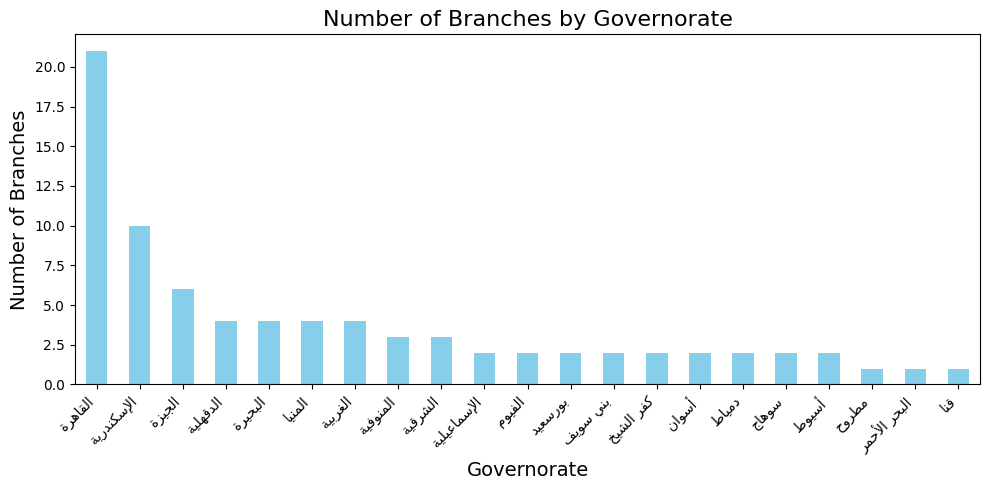

In [8]:
dic_br.index = [
    get_display(arabic_reshaper.reshape(str(name)))
    for name in dic_br.index
]

dic_br.plot(kind='bar', figsize=(10, 5), color='skyblue')

plt.title('Number of Branches by Governorate', fontsize=16)
plt.xlabel('Governorate', fontsize=14)
plt.ylabel('Number of Branches', fontsize=14)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [9]:
len(dic_br.keys())

21

In [10]:
df_pr = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\PRODUCT_CATALOG_PUBLIC_REFERENCE.csv')

In [11]:
df_sales_it = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\sales_order_items.csv')

In [12]:
df_pr.columns

Index(['product_id', 'product_name_ar', 'category', 'listed_price_EGP'], dtype='object')

In [13]:
df_re = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\sales_returns.csv')

In [14]:
or_it = pd.merge(df_sales_it , df_pr, how='left', left_on='product_id', right_on='product_id')

In [15]:
or_it = or_it[~or_it['sales_order_id'].isin(df_re['sales_order_id'])]

In [16]:
or_it.columns

Index(['sales_line_id', 'sales_order_id', 'order_date', 'branch_id', 'sku_id',
       'product_id', 'quantity', 'unit_price_EGP', 'gross_line_EGP',
       'discount_line_EGP', 'net_line_EGP', 'unit_cost_EGP', 'margin_EGP',
       'product_name_ar', 'category', 'listed_price_EGP'],
      dtype='object')

In [17]:
or_it['sku_id'].value_counts()

sku_id
SKU000407    3557
SKU000297    3504
SKU000597    3504
SKU000427    3502
SKU000666    3481
             ... 
SKU000034     353
SKU000171     353
SKU000272     352
SKU000197     344
SKU000158     342
Name: count, Length: 695, dtype: int64

In [18]:
product_share = round(or_it.groupby('category').agg({'quantity': 'sum'})/(or_it['quantity'].sum())*100, 2).sort_values(by='quantity', ascending=False)

Text(0.5, 1.0, 'Product Share by Category')

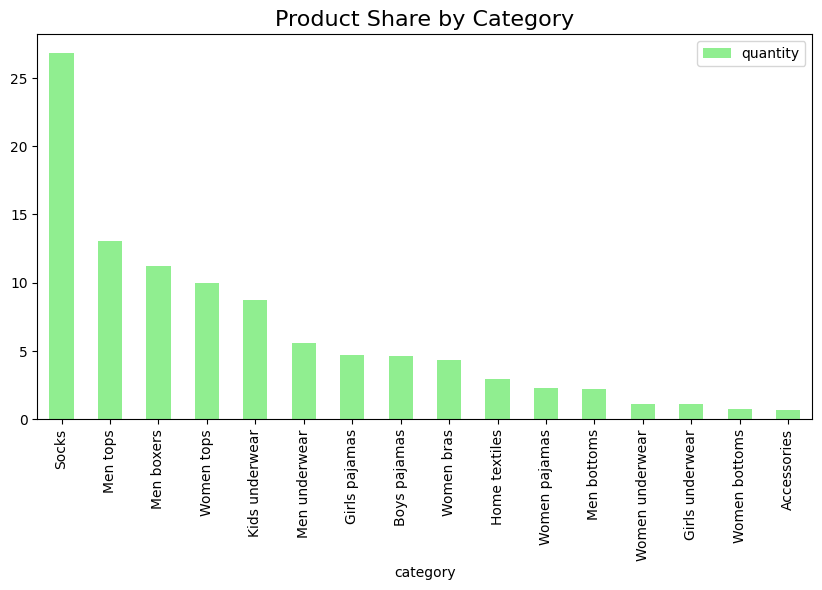

In [19]:
product_share.plot(kind='bar', figsize=(10, 5), color='lightgreen')
plt.title('Product Share by Category', fontsize=16)

In [20]:
product_share_pr = round(or_it.groupby('category').agg({'margin_EGP': 'sum'})/(or_it['margin_EGP'].sum())*100, 2).sort_values(by='margin_EGP', ascending=False)

In [36]:
total_margin = or_it['margin_EGP'].sum()
print(f'The total margin is {total_margin} EGP')

The total margin is 305281924.00999993 EGP


In [37]:
number_of_skus = or_it['sku_id'].nunique()
print(f'The number of unique SKUs sold is {number_of_skus}')

The number of unique SKUs sold is 695


In [38]:
number_of_categories = or_it['category'].nunique()
print(f'The number of unique categories sold is {number_of_categories}')

The number of unique categories sold is 16


In [23]:
product_share_pr

,margin_EGP
category,
Men boxers,22.95
Men tops,19.59
Socks,13.87
Men underwear,6.35
Women pajamas,5.93
Women tops,5.77
Girls pajamas,4.64
Boys pajamas,4.56
Home textiles,4.00


<Axes: xlabel='category'>

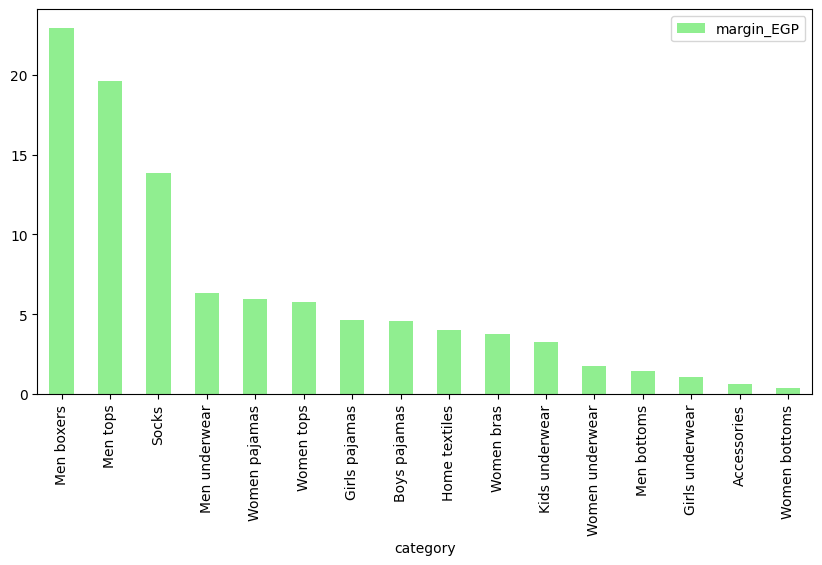

In [24]:
product_share_pr.plot(kind='bar', figsize=(10, 5), color='lightgreen')

In [25]:
or_it.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1078202 entries, 0 to 1138535
Data columns (total 16 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   sales_line_id      1078202 non-null  object 
 1   sales_order_id     1078202 non-null  object 
 2   order_date         1078202 non-null  object 
 3   branch_id          1078202 non-null  object 
 4   sku_id             1078202 non-null  object 
 5   product_id         1078202 non-null  object 
 6   quantity           1078202 non-null  int64  
 7   unit_price_EGP     1078202 non-null  float64
 8   gross_line_EGP     1078202 non-null  float64
 9   discount_line_EGP  1078202 non-null  float64
 10  net_line_EGP       1078202 non-null  float64
 11  unit_cost_EGP      1078202 non-null  float64
 12  margin_EGP         1078202 non-null  float64
 13  product_name_ar    1078202 non-null  object 
 14  category           1078202 non-null  object 
 15  listed_price_EGP   1078202 non-null  

In [26]:
or_it['order_date'] = pd.to_datetime(or_it['order_date'])

<Axes: xlabel='order_date'>

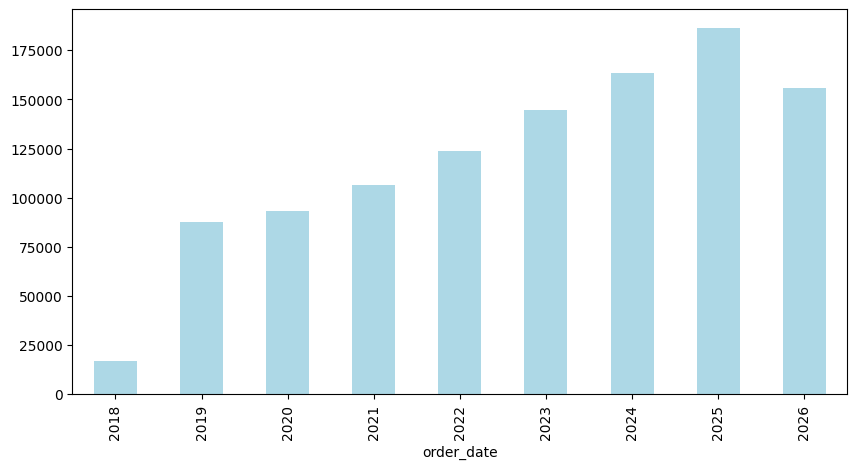

In [27]:
or_it['order_date'].dt.year.value_counts().sort_index().plot(kind='bar', figsize=(10, 5), color='lightblue')

In [28]:
or_it['order_date'].describe()

count                          1078202
mean     2023-06-17 07:55:54.097284608
min                2018-10-19 00:00:00
25%                2021-09-11 00:00:00
50%                2023-10-21 00:00:00
75%                2025-05-24 00:00:00
max                2026-10-18 00:00:00
Name: order_date, dtype: object

 Year      Profit  Gross_Sales  Profit_Change  Profit_Change_%
 2019  5920509.43  16165850.47            NaN              NaN
 2020  7073898.79  19317036.07     1153389.36            19.48
 2021  9093590.62  24737118.00     2019691.83            28.55
 2022 14266593.79  39142524.42     5173003.17            56.89
 2023 23198984.85  63243054.63     8932391.06            62.61
 2024 41267990.64 112258339.77    18069005.79            77.89
 2025 65231087.85 177901650.67    23963097.21            58.07
 2026 86625634.74 236148255.35    21394546.89            32.80


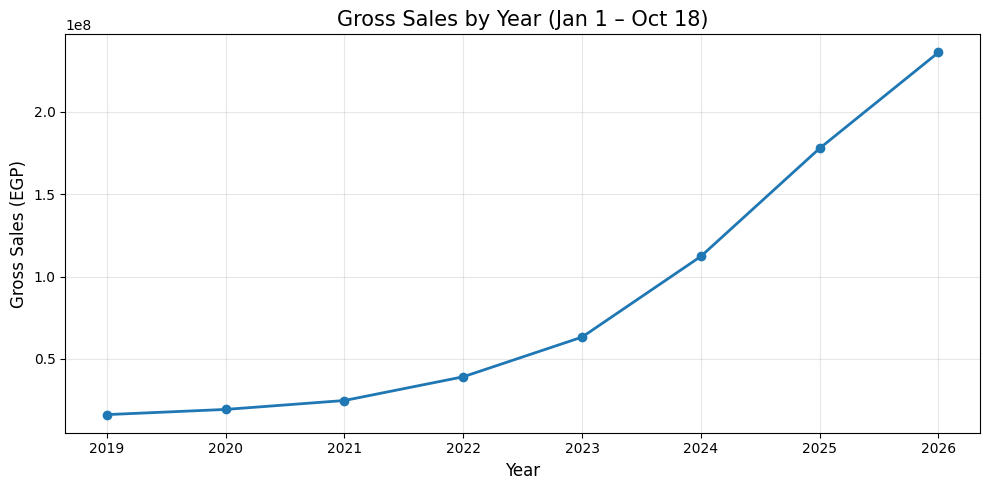

In [29]:
end_month = 10
end_day = 18

df = or_it[
    (or_it['order_date'].dt.month < end_month) |
    (
        (or_it['order_date'].dt.month == end_month) &
        (or_it['order_date'].dt.day <= end_day)
    )
].copy()

df = df[df['order_date'].dt.year.between(
    or_it['order_date'].dt.year.min(), 2026
)]

# Calculate yearly Profit and Gross Sales
yearly = (
    df.groupby(df['order_date'].dt.year)
    .agg(
        Profit=('margin_EGP', 'sum'),
        Gross_Sales=('gross_line_EGP', 'sum')
    )
    .reset_index()
    .rename(columns={'order_date': 'Year'})
)

yearly = yearly.rename(columns={yearly.columns[0]: 'Year'})

# Calculate absolute and percentage change in Profit vs last year
yearly['Profit_Change'] = yearly['Profit'].diff()

yearly['Profit_Change_%'] = (
    yearly['Profit'].pct_change() * 100
)

print(yearly.round(2).to_string(index=False))

# Line plot for Gross Sales
plt.figure(figsize=(10, 5))

plt.plot(
    yearly['Year'],
    yearly['Gross_Sales'],
    marker='o',
    linewidth=2
)

plt.title('Gross Sales by Year (Jan 1 – Oct 18)', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Gross Sales (EGP)', fontsize=12)
plt.xticks(yearly['Year'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:
yearly.to_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\yearly_profit_gross_sales.csv', index=False)

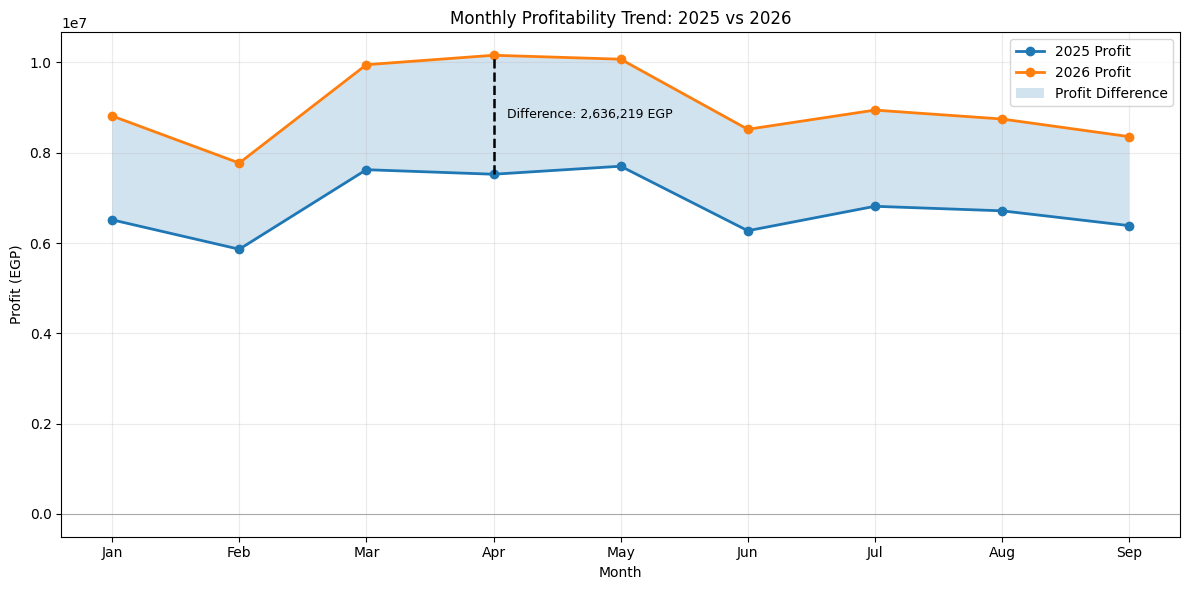

In [30]:

import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
df = or_it.copy()
df['order_date'] = pd.to_datetime(df['order_date'])

df = df[
    (df['order_date'].dt.year.isin([2025, 2026])) &
    (df['order_date'].dt.month <= 9)
].copy()

# Monthly profit
monthly_profit = (
    df.groupby([
        df['order_date'].dt.year.rename('Year'),
        df['order_date'].dt.month.rename('Month')
    ])['margin_EGP']
    .sum()
    .unstack('Year')
    .reindex(range(1, 10))
)

# Ensure both years are present
monthly_profit = monthly_profit.reindex(columns=[2025, 2026])

# Difference: 2026 vs 2025
monthly_profit['Difference'] = (
    monthly_profit[2026] - monthly_profit[2025]
)

months = monthly_profit.index
profit_2025 = monthly_profit[2025]
profit_2026 = monthly_profit[2026]
difference = monthly_profit['Difference']

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    months, profit_2025,
    marker='o', linewidth=2,
    label='2025 Profit'
)

ax.plot(
    months, profit_2026,
    marker='o', linewidth=2,
    label='2026 Profit'
)

# Shade the area between the two lines
ax.fill_between(
    months,
    profit_2025,
    profit_2026,
    alpha=0.2,
    label='Profit Difference'
)

# Find largest positive and negative differences
valid_diff = difference.dropna()

if not valid_diff.empty:
    peak_months = []

    max_positive = valid_diff.max()
    min_negative = valid_diff.min()

    if max_positive > 0:
        peak_months.append((valid_diff.idxmax(), max_positive))

    if min_negative < 0:
        peak_months.append((valid_diff.idxmin(), min_negative))

    # Annotate the difference at each peak
    for month, diff_value in peak_months:
        y1 = profit_2025.loc[month]
        y2 = profit_2026.loc[month]

        ax.vlines(
            x=month,
            ymin=min(y1, y2),
            ymax=max(y1, y2),
            color='black',
            linestyle='--',
            linewidth=1.8
        )

        ax.annotate(
            f'Difference: {diff_value:,.0f} EGP',
            xy=(month, (y1 + y2) / 2),
            xytext=(10, 0),
            textcoords='offset points',
            fontsize=9,
            va='center'
        )

month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May',
    'Jun', 'Jul', 'Aug', 'Sep'
]

ax.set_xticks(months)
ax.set_xticklabels(month_names)

ax.set_title('Monthly Profitability Trend: 2025 vs 2026')
ax.set_xlabel('Month')
ax.set_ylabel('Profit (EGP)')
ax.axhline(0, color='gray', linewidth=0.8, alpha=0.6)
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


In [31]:
or_br = pd.merge(df_br, df_sales_it, how='left', left_on='branch_id', right_on='branch_id')
or_br = or_br[~or_br['sales_order_id'].isin(df_re['sales_order_id'])]

In [32]:
returned_lines = df_re['sales_line_id'].dropna().unique()

# 2. Copy sales data
sales = df_sales_it.copy()

# 3. Mark returned products
sales['is_returned'] = sales['sales_line_id'].isin(returned_lines)

# 4. Calculate profit excluding returned products
sales['net_profit'] = sales['margin_EGP'].where(
    ~sales['is_returned'], 0
)

# 5. Aggregate branch performance
branch_performance = (
    sales.groupby('branch_id')
    .agg(
        Profit=('net_profit', 'sum'),
        Total_Orders=('sales_order_id', 'nunique'),
        Returned_Orders=(
            'sales_order_id',
            lambda x: x[sales.loc[x.index, 'is_returned']].nunique()
        )
    )
    .reset_index()
)

branch_performance['Completed_Orders'] = (
    branch_performance['Total_Orders']
    - branch_performance['Returned_Orders']
)

branch_performance = branch_performance[
    ['branch_id', 'Profit', 'Completed_Orders', 'Returned_Orders']
]

print(branch_performance)

   branch_id      Profit  Completed_Orders  Returned_Orders
0      BR001  4005739.69              6408              350
1      BR002  3749642.10              6416              384
2      BR003  4249048.43              6573              359
3      BR004  4069054.14              6314              359
4      BR005  3792441.12              6280              367
..       ...         ...               ...              ...
75     BR076  3850955.80              6315              353
76     BR077  3922157.89              6449              322
77     BR078  4008801.44              6489              357
78     BR079  4082840.47              6430              339
79     BR080  3952792.19              6307              360

[80 rows x 4 columns]


In [33]:
branch_performance = pd.merge(
    branch_performance,
    df_br[['branch_id', 'branch_name_ar']],
    on='branch_id',
    how='left'
)

branch_performance = branch_performance[
    ['branch_id', 'branch_name_ar', 'Profit',
     'Completed_Orders', 'Returned_Orders']
]

print(branch_performance)

   branch_id      branch_name_ar      Profit  Completed_Orders  \
0      BR001             الزمالك  4005739.69              6408   
1      BR002         السيدة زينب  3749642.10              6416   
2      BR003  القطامية داون تاون  4249048.43              6573   
3      BR004          الرحاب مول  4069054.14              6314   
4      BR005   المعادي جراند مول  3792441.12              6280   
..       ...                 ...         ...               ...   
75     BR076           وسط البلد  3850955.80              6315   
76     BR077        كورنيش النيل  3922157.89              6449   
77     BR078          شرق البندر  4008801.44              6489   
78     BR079           ساحل سليم  4082840.47              6430   
79     BR080             الجامعة  3952792.19              6307   

    Returned_Orders  
0               350  
1               384  
2               359  
3               359  
4               367  
..              ...  
75              353  
76              322  
77       

In [34]:
df_br.head()

,branch_id,branch_name_ar,governorate_ar,city_ar,address_ar,retail_location_type,opening_date
0,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,9/14/2019
1,BR002,السيدة زينب,القاهرة,السيدة زينب,229 شارع بورسعيد، السيدة زينب,Point of sale / reseller,2/19/2019
2,BR003,القطامية داون تاون,القاهرة,القطامية,شارع التسعين، مول داون تاون، القطامية,Retail branch,2/12/2020
3,BR004,الرحاب مول,القاهرة,الرحاب,المرحلة الثالثة، مول الرحاب,Point of sale / reseller,8/14/2019
4,BR005,المعادي جراند مول,القاهرة,المعادي,شارع 250، جراند مول، المعادي,Retail branch,11/16/2018


In [35]:
branch_performance = branch_performance.sort_values(
    by=['Profit', 'Returned_Orders'],
    ascending=[False, True]
).reset_index(drop=True)

branch_performance.to_csv(
    'branch_performance.csv',
    index=False,
    encoding='utf-8-sig'
)